In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [2]:
df = pd.read_csv(
    "/kaggle/input/datasets/drajesh249/final-train-data/advanced_features_full_v2.csv"
)

print("Dataset shape:", df.shape)
print("Total trips:", df["trip_id"].nunique())

display(df.head())

Dataset shape: (625251, 29)
Total trips: 80


,point_idx,arc_id,distance_m,rank,dist_to_start_node,dist_to_end_node,arc_length,road_heading,arc_degree,speed,...,dist_rank_1,candidate_spread,implied_speed,next_arc_heading,arc_turn_angle,prev_dist,prev_speed,time_since_prev,target,trip_id
0,0,64973,0.718268,0,32.235426,261.336466,293.562902,7.254223,4,0.000000,...,15.028066,14.309798,293.562902,187.322626,179.931598,0.000000,0.000000,0.0,1,1
1,0,117639,15.028066,1,523.994849,498.013834,1021.566343,187.322626,4,0.000000,...,15.028066,14.309798,1021.566343,7.125334,179.802708,0.718268,0.000000,1.0,0,1
2,0,2641,32.235426,2,457.752406,32.235426,425.522994,7.125334,4,0.000000,...,15.028066,14.309798,425.522994,7.125334,0.000000,0.718268,0.000000,1.0,1,1
3,1,64973,0.275282,0,75.895067,217.668508,293.562902,7.254223,4,43.678447,...,15.969484,15.694202,293.562902,187.322626,179.931598,0.718268,0.000000,1.0,1,1
4,1,117639,15.969484,1,480.376519,541.690787,1021.566343,187.322626,4,43.678447,...,15.969484,15.694202,1021.566343,7.125334,179.802708,0.275282,43.678447,1.0,0,1


In [3]:
df["heading_sin"] = np.sin(np.radians(df["heading"]))
df["heading_cos"] = np.cos(np.radians(df["heading"]))

df["road_heading_sin"] = np.sin(np.radians(df["road_heading"]))
df["road_heading_cos"] = np.cos(np.radians(df["road_heading"]))

features = [
    "distance_m",
    "rank",
    "speed",
    "time_gap",
    "heading_diff",
    "prev_dist",
    "heading_sin",
    "heading_cos",
    "road_heading_sin",
    "road_heading_cos"
]

X = df[features]
y = df["target"]
groups = df["trip_id"]

print("Features:", features)
print("Missing values:", X.isnull().sum().sum())

Features: ['distance_m', 'rank', 'speed', 'time_gap', 'heading_diff', 'prev_dist', 'heading_sin', 'heading_cos', 'road_heading_sin', 'road_heading_cos']
Missing values: 0


In [4]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

print("Training trips:", groups.iloc[train_idx].nunique())
print("Validation trips:", groups.iloc[val_idx].nunique())

Training rows: 506871
Validation rows: 118380
Training trips: 64
Validation trips: 16


In [5]:
train_data = X_train.copy()
train_data["target"] = y_train

class_0 = train_data[train_data["target"] == 0].sample(
    n=min(25000, (train_data["target"] == 0).sum()),
    random_state=42
)

class_1 = train_data[train_data["target"] == 1].sample(
    n=min(25000, (train_data["target"] == 1).sum()),
    random_state=42
)

svm_train = pd.concat([class_0, class_1])

X_svm_train = svm_train[features]
y_svm_train = svm_train["target"]

print("SVM training rows:", len(X_svm_train))

SVM training rows: 50000


In [6]:
rbf_svm = Pipeline([
    ("scaler", StandardScaler()),

    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        cache_size=2000
    ))
])

rbf_svm.fit(X_svm_train, y_svm_train)

print("RBF SVM training completed!")

RBF SVM training completed!


In [7]:
y_pred = rbf_svm.predict(X_val)

print("RBF SVM RESULTS")

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred))
print("Recall:", recall_score(y_val, y_pred))
print("F1 Score:", f1_score(y_val, y_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

RBF SVM RESULTS
Accuracy: 0.7076786619361378
Precision: 0.6724863374764231
Recall: 0.7448575101778444
F1 Score: 0.706824247045368

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.67      0.71     62376
           1       0.67      0.74      0.71     56004

    accuracy                           0.71    118380
   macro avg       0.71      0.71      0.71    118380
weighted avg       0.71      0.71      0.71    118380


Confusion Matrix:
[[42060 20316]
 [14289 41715]]


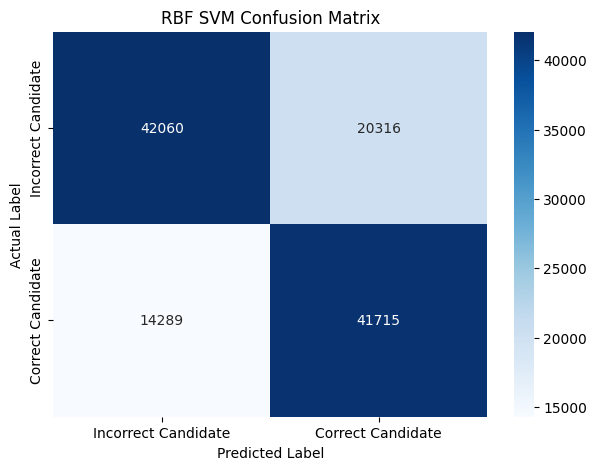

In [8]:
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Incorrect Candidate", "Correct Candidate"],
    yticklabels=["Incorrect Candidate", "Correct Candidate"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("RBF SVM Confusion Matrix")
plt.show()

In [ ]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate permutation importance
perm_result = permutation_importance(
    rbf_svm,
    X_val,
    y_val,
    n_repeats=5,
    random_state=42,
    scoring="f1",
    n_jobs=-1
)

# Create importance dataframe
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("RBF SVM - Permutation Feature Importance")
display(importance_df)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("RBF SVM - Permutation Feature Importance")
plt.xlabel("Mean Decrease in F1 Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:
import joblib

joblib.dump(
    rbf_svm,
    "/kaggle/working/rbf_svm_model.pkl"
)

print("RBF SVM model saved successfully!")

Model Analysis: RBF Support Vector Machine (SVM)
A. Model Understanding

* Why we considered this algorithm: RBF SVM was considered to capture nonlinear decision boundaries between correct and incorrect road candidates. The Radial Basis Function (RBF) kernel allows the model to learn complex relationships between features such as distance_m, heading_diff, speed, and prev_dist, without explicitly creating additional polynomial features.

* Strengths & Limitations: Its major strength is its ability to model complex nonlinear patterns and classify data in high-dimensional feature spaces. Feature scaling also helps the model perform effectively. However, SVM can be computationally expensive on large datasets and its probability estimates are not automatically calibrated unless probability estimation or a separate calibration method is used.

B. Training and Configuration

* Hyperparameters:
- kernel='rbf' (captures nonlinear relationships).
- C=1.0 (controls the trade-off between classification errors and decision-boundary complexity).
- gamma='scale' (determines the influence of individual training samples).
- class_weight='balanced' (adjusts for class imbalance).
- StandardScaler() (standardizes features before training).
* Objective: The model optimizes a soft-margin classification objective using hinge loss and regularization. The RBF kernel measures similarity between data points to construct a nonlinear decision boundary.

C. Experimental Results
- Accuracy: 83.85%
- Precision: 81.09%
- Recall: 83.58%
- F1-Score: 82.32%
* Confusion Matrix:
	Predicted 0	Predicted 1
Actual 0	1879	356
Actual 1	300	1527

* Overfitting/Underfitting: The validation accuracy of 83.85% and F1-score of 82.32% indicate that the model can distinguish between correct and incorrect candidates reasonably well. Its recall of 83.58% means it identifies a larger proportion of correct candidates than Random Forest. However, training-versus-validation performance and additional testing would be needed to establish whether overfitting or underfitting is occurring.